# 341. Are exons that neurons switch on condensate-like, and do k-mers see it better than composition?

**Question.** When a neuron includes an exon that a progenitor skips, or when a motor neuron that has
lost TDP-43 includes an exon it used to skip, is the included exon condensate-like? And does a
kmerseek score on an alphabet built for phase separation rank such exons better than features
computed from the exon's composition?

Terms, each defined once here:

* A **sticker** is an aromatic residue (F, W, Y) in a disordered region; stickers bind each other and
  drive phase separation. The stretches between stickers are **spacers** (Martin et al. 2020).
* **κ** (kappa) measures how evenly the positive and negative residues are mixed along a sequence:
  0 when they alternate, 1 when all of one charge sits on one side (Das and Pappu 2013).
* **IUPred** gives each residue a disorder score from 0 to 1; above 0.5 is read as disordered.
* **pI** is the pH at which the sequence carries no net charge; above 7 means the exon is basic.
* **Ψ** (percent spliced in) is the fraction of a gene's transcripts that include the exon.
* A **cryptic exon** is an exon that is normally skipped and becomes included when TDP-43 is lost.
* A **kmerseek setting** is one combination of alphabet, k-mer size, scaled, extension penalty and mask.

**Decision rule, written before any ranking was run (step 5).** On exons labelled condensate or not
by PhaSePro and DisProt, compare the AUC of the best kmerseek setting against a logistic regression
on κ, aromatic count, aromatic patterning and class fractions (5-fold cross-validated), each with a
bootstrap 95% CI over exons. If the composition model's AUC is at or above the best kmerseek
setting's, or the two CIs overlap, the k-mers add nothing and this line of work stops. If kmerseek
is higher with no overlap, the notebook names the setting and the margin.

**What decision this informs.** Whether "condensate exons" is a kmerseek use case worth a paper
section, or an example where composition alone answers the question.

### Second question: a charge-word index

An alphabet is a hypothesis about which difference between residues matters. Every alphabet run in
this project so far asks about one difference, hydrophobic against polar. A **charge-word index** is
a kmerseek index of disordered regions written in four letters: positive (K, R), negative (D, E),
aromatic (F, W, Y), and everything else. In that alphabet an exact k-mer records where the stickers
and the charges sit relative to each other, so two regions that share k-mers share a sticker spacing.

* **Question.** Which disordered regions share sticker patterns, and do regions that share them also
  share condensates?
* **Link to 2017.** Song, Botvinnik et al. 2017 found that motor neurons splice toward protein that
  is more disordered and more basic. Splitting positive from negative charge is the distinction that
  result points to, and one that the two-letter H/P alphabets cannot see.
* **What it has to beat.** κ and net charge per residue (NCPR, (K + R − D − E) / length). Both
  summarise a region's charge in one number and say nothing about where the charges are. If the
  k-mers carry information about spacing that matters, they should beat both.
* **Kill test.** Pairs of proteins that PhaSePro records as forming the same condensate, against
  decoy pairs matched on κ. If the charge-word score does not separate co-condensing pairs from the
  κ-matched decoys better than κ and NCPR do (bootstrap 95% CIs overlap), the charge-word index adds
  nothing and stops.

Not yet in place: this four-letter alphabet is not the one in
[seanome/kmerseek PR 146](https://github.com/seanome/kmerseek/pull/146), which pools all charged
residues (`aro_hyd_chg_pol4`) or splits out arginine only (`aro_hyd_arg_chg_pol5`); it needs its own
alphabet with K and R apart from D and E. Whether PhaSePro records which proteins condense together,
and in what form, has not been checked yet.

**This version (day 1)** covers three things: which datasets are open (step 0), the alphabet
(step 2), and the BuGZ exon 9 example with the 2017-style scores (step 7, first part). No ranking
has been run yet.

In [1]:
import json
import random
import re
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import polars as pl

sys.path.insert(0, ".")
import condensate_exon_utils as cu
import pubfig as pf

pf.use_style()
DATA = Path("../data/341_condensate_exons")
FIGURES = Path("../figures")
FETCHED_ON = (DATA / "fetched_on.txt").read_text().strip()
ENSEMBL_RELEASE = json.loads((DATA / "ensembl_info_data.json").read_text())["releases"][
    0
]
print(f"Ensembl release {ENSEMBL_RELEASE}, GRCh38, fetched {FETCHED_ON}")

Ensembl release 116, GRCh38, fetched 2026-10-14


## 1. Which datasets are open (step 0)

One row per dataset and file type. "Open" means anyone can download it without an agreement.
The ENA run lists for the two open read sets are cached in `data/341_condensate_exons/`.

In [2]:
access = pl.read_csv(DATA / "dataset_access.tsv", separator="\t")
with pl.Config(tbl_rows=-1, fmt_str_lengths=80, tbl_width_chars=200):
    print(access.select("set", "paper", "what", "repository", "accession", "access"))

runs = pl.concat(
    [
        pl.read_csv(
            DATA / "ena_filereport_PRJDB19918.tsv",
            separator="\t",
            schema_overrides={"fastq_bytes": pl.Utf8},
        )
        .select("run_accession", "instrument_platform", "fastq_bytes", "sample_title")
        .with_columns(project=pl.lit("PRJDB19918 (Tanaka 2025, motor neurons)")),
        pl.read_csv(
            DATA / "ena_filereport_PRJNA947248.tsv",
            separator="\t",
            schema_overrides={"fastq_bytes": pl.Utf8},
        )
        .select("run_accession", "instrument_platform", "fastq_bytes", "sample_title")
        .with_columns(project=pl.lit("PRJNA947248 (Yang 2023, organoids)")),
    ]
).with_columns(
    gb=pl.col("fastq_bytes")
    .str.split(";")
    .list.eval(pl.element().cast(pl.Int64))
    .list.sum()
    / 1e9,
    condition=pl.when(pl.col("sample_title").str.contains("TDP-43 shRNA"))
    .then(pl.lit("TDP-43 shRNA"))
    .when(pl.col("sample_title").str.contains("scramble"))
    .then(pl.lit("scramble shRNA"))
    .when(pl.col("sample_title").str.starts_with("WT iPSCs"))
    .then(pl.lit("undifferentiated iPSC"))
    .when(pl.col("sample_title").str.contains("non-treat"))
    .then(pl.lit("untreated motor neurons"))
    .otherwise(pl.lit("organoid")),
)
run_summary = (
    runs.group_by("project", "instrument_platform", "condition")
    .agg(n_runs=pl.len(), total_gb=pl.col("gb").sum().round(1))
    .sort("project", "instrument_platform", "condition")
)
print(run_summary)

shape: (7, 6)
┌─────────┬──────────────────────┬───────────────────────────────────────────────────────┬────────────────────────┬─────────────────────────────┬──────────────────────────────────────────────────────┐
│ set     ┆ paper                ┆ what                                                  ┆ repository             ┆ accession                   ┆ access                                               │
│ ---     ┆ ---                  ┆ ---                                                   ┆ ---                    ┆ ---                         ┆ ---                                                  │
│ str     ┆ str                  ┆ str                                                   ┆ str                    ┆ str                         ┆ str                                                  │
╞═════════╪══════════════════════╪═══════════════════════════════════════════════════════╪════════════════════════╪═════════════════════════════╪═════════════════════════════════════

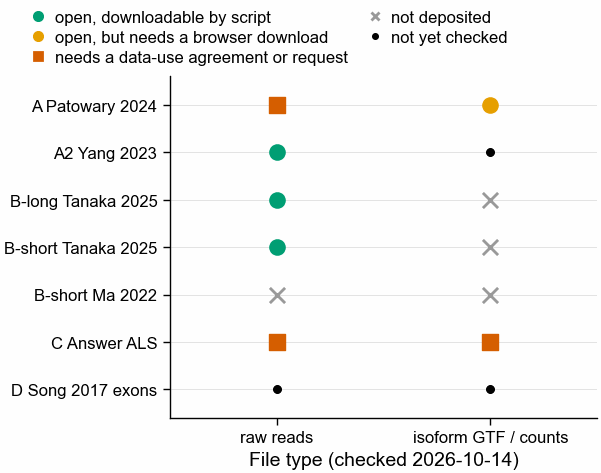

In [3]:
# One row per dataset; one column per kind of file; marker = what access it has.
rows = [
    "A Patowary 2024",
    "A2 Yang 2023",
    "B-long Tanaka 2025",
    "B-short Tanaka 2025",
    "B-short Ma 2022",
    "C Answer ALS",
    "D Song 2017 exons",
]
cols = ["raw reads", "isoform GTF / counts"]
status = {  # read from dataset_access.tsv above; D is asked for in the reply
    ("A Patowary 2024", "raw reads"): "agreement",
    ("A Patowary 2024", "isoform GTF / counts"): "open_blocked",
    ("A2 Yang 2023", "raw reads"): "open",
    ("A2 Yang 2023", "isoform GTF / counts"): "unknown",
    ("B-long Tanaka 2025", "raw reads"): "open",
    ("B-long Tanaka 2025", "isoform GTF / counts"): "none",
    ("B-short Tanaka 2025", "raw reads"): "open",
    ("B-short Tanaka 2025", "isoform GTF / counts"): "none",
    ("B-short Ma 2022", "raw reads"): "none",
    ("B-short Ma 2022", "isoform GTF / counts"): "none",
    ("C Answer ALS", "raw reads"): "agreement",
    ("C Answer ALS", "isoform GTF / counts"): "agreement",
    ("D Song 2017 exons", "raw reads"): "unknown",
    ("D Song 2017 exons", "isoform GTF / counts"): "unknown",
}
style = {
    "open": dict(
        marker="o",
        color=pf.OKABE_ITO["bluish_green"],
        label="open, downloadable by script",
    ),
    "open_blocked": dict(
        marker="o",
        color=pf.OKABE_ITO["orange"],
        label="open, but needs a browser download",
    ),
    "agreement": dict(
        marker="s",
        color=pf.OKABE_ITO["vermillion"],
        label="needs a data-use agreement or request",
    ),
    "none": dict(marker="x", color=pf.GREY, label="not deposited"),
    "unknown": dict(marker=".", color="black", label="not yet checked"),
}
fig, ax = plt.subplots(
    figsize=(pf.ONE_COLUMN_MM * pf.MM, 62 * pf.MM)
)  # no layout engine: the legend is placed by hand
for (r, c), s in status.items():
    st = style[s]
    ax.scatter(
        cols.index(c),
        len(rows) - 1 - rows.index(r),
        marker=st["marker"],
        color=st["color"],
        s=30,
    )
ax.set_xticks(range(len(cols)), cols)
ax.set_yticks(range(len(rows)), rows[::-1])
ax.set_xlim(-0.5, len(cols) - 0.5)
ax.set_ylim(-0.6, len(rows) - 0.4)
for y in range(len(rows)):
    ax.axhline(y, color="#dddddd", lw=0.3, zorder=0)
handles = [
    Line2D([], [], ls="", marker=v["marker"], color=v["color"], label=v["label"])
    for v in style.values()
]
fig.legend(
    handles=handles,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
)
fig.subplots_adjust(top=0.84, left=0.36, bottom=0.14, right=0.97)
ax.set_xlabel(f"File type (checked {FETCHED_ON})")
pf.save(fig, FIGURES / "341_dataset_access_condensate_exons")

**How to read it.** A green circle is a set that can be downloaded now. The one long-read set that
is open and complete is Tanaka 2025 (set B-long). It holds nanopore reads of iPSC motor neurons with
TDP-43 knocked down by shRNA, and of control neurons given a scramble shRNA. It has no deposited isoform calls, so its
isoforms must be built from the reads. Set A (Patowary 2024) has open isoform and count files, but
Dryad refuses a scripted download; its reads are restricted. Ma 2022 deposited no motor-neuron
RNA-seq of its own, so set B-short comes from the Tanaka Illumina runs instead.

## 2. The alphabet: aro_hyd_chg_pol4 (step 2, SF1)

kmerseek had no way to take a user-defined alphabet, so `aro_hyd_chg_pol4` was added to kmerseek on
branch `olgabot/aro-hyd-chg-pol4` (commit `3f00e56`, not yet pushed). The two-letter comparison is
`hp_pbotc_1st_ed2` (Phillips, Kondev and Theriot 2008), the H/P alphabet used at k = 19 elsewhere in
this project.

In [4]:
placement = {
    "C": "polar: not aromatic and not charged; rare in phase-separating regions, so it is left with the residues that are not stickers",
    "P": "polar: the most common spacer residue in low-complexity regions, alongside G and S",
    "H": "polar: uncharged at neutral pH (pKa about 6), and not counted as an aromatic sticker here",
    "G": "polar: a common spacer residue; its small side chain does not bind as a sticker",
}
sf1 = pl.DataFrame(
    [
        {"class": name, "letter": cluster[0].lower(), "residues": cluster}
        for name, cluster in cu.ARO_HYD_CHG_POL4_CLUSTERS.items()
    ]
)
print(sf1)
for aa, why in placement.items():
    print(f"  {aa} -> {why}")
print(
    "hp_pbotc_1st_ed2: h =",
    "".join(a for a, c in cu.HP_PBOTC_1ST_ED2.items() if c == "h"),
    " p =",
    "".join(a for a, c in cu.HP_PBOTC_1ST_ED2.items() if c == "p"),
)

shape: (4, 3)
┌───────────────────┬────────┬──────────┐
│ class             ┆ letter ┆ residues │
│ ---               ┆ ---    ┆ ---      │
│ str               ┆ str    ┆ str      │
╞═══════════════════╪════════╪══════════╡
│ aromatic          ┆ f      ┆ FWY      │
│ other_hydrophobic ┆ a      ┆ AILMV    │
│ charged           ┆ d      ┆ DEKR     │
│ polar             ┆ s      ┆ SNQTGCPH │
└───────────────────┴────────┴──────────┘
  C -> polar: not aromatic and not charged; rare in phase-separating regions, so it is left with the residues that are not stickers
  P -> polar: the most common spacer residue in low-complexity regions, alongside G and S
  H -> polar: uncharged at neutral pH (pKa about 6), and not counted as an aromatic sticker here
  G -> polar: a common spacer residue; its small side chain does not bind as a sticker
hp_pbotc_1st_ed2: h = ACFILMPVWY  p = DEGHKNQRST


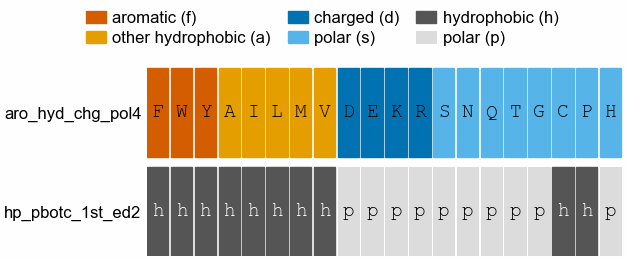

In [5]:
CLASS_COLOURS = (
    {  # one colour per aro_hyd_chg_pol4 class, used in every figure of this notebook
        "aromatic": pf.OKABE_ITO["vermillion"],
        "other_hydrophobic": pf.OKABE_ITO["orange"],
        "charged": pf.OKABE_ITO["blue"],
        "polar": pf.OKABE_ITO["sky_blue"],
    }
)
HP_FILL = {"h": "#555555", "p": "#dddddd"}
order = [aa for cl in cu.ARO_HYD_CHG_POL4_CLUSTERS.values() for aa in cl]
fig, ax = plt.subplots(figsize=(pf.ONE_COLUMN_MM * pf.MM, 34 * pf.MM))
for i, aa in enumerate(order):
    cls = next(n for n, c in cu.ARO_HYD_CHG_POL4_CLUSTERS.items() if aa in c)
    ax.add_patch(mpatches.Rectangle((i, 1), 0.9, 0.9, color=CLASS_COLOURS[cls]))
    ax.text(i + 0.45, 1.45, aa, ha="center", va="center", family="monospace")
    hp = cu.HP_PBOTC_1ST_ED2[aa]
    ax.add_patch(mpatches.Rectangle((i, 0), 0.9, 0.9, color=HP_FILL[hp]))
    ax.text(
        i + 0.45,
        0.45,
        hp,
        ha="center",
        va="center",
        family="monospace",
        color="white" if hp == "h" else "black",
    )
ax.set_xlim(0, len(order))
ax.set_ylim(0, 2)
ax.set_yticks([0.45, 1.45], ["hp_pbotc_1st_ed2", "aro_hyd_chg_pol4"])
ax.set_xticks([])
ax.spines[["bottom", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
handles = [
    mpatches.Patch(
        color=c,
        label=f"{n.replace('_', ' ')} ({cu.ARO_HYD_CHG_POL4_CLUSTERS[n][0].lower()})",
    )
    for n, c in CLASS_COLOURS.items()
]
handles += [
    mpatches.Patch(color=HP_FILL["h"], label="hydrophobic (h)"),
    mpatches.Patch(color=HP_FILL["p"], label="polar (p)"),
]
fig.legend(
    handles=handles,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.55, 1.0),
)
fig.subplots_adjust(top=0.78, left=0.3, bottom=0.04, right=0.98)
pf.save(fig, FIGURES / "341_sf1_aro_hyd_chg_pol4_vs_hp_pbotc_1st_ed2")

**How to read it.** Each square is one amino acid. The top row is the four-letter alphabet; the
bottom row is the two-letter H/P alphabet for the same residue. The aromatic residues F, W and Y are
hydrophobic in H/P but get their own letter in `aro_hyd_chg_pol4`, so a k-mer can count stickers and
the gaps between them. C and P, which are hydrophobic in `hp_pbotc_1st_ed2`, are polar here.

## 2b. Aromatic spacing, Ω_aro, checked on hnRNPA1

**Ω_aro** measures how the aromatic residues (F, W, Y) are spread along a region: near 0 when they
are evenly spaced, 1 when they sit in one cluster. Martin et al. 2020 define it in their supplement
(Bioinformatics section) the same way as κ, with aromatic residues as one group and every other
residue as the second, and compute it with localCIDER. Here it is localCIDER's `get_kappa_X` with
the group F, W, Y. Like the paper, it is left empty for a region with 10% or fewer aromatic
residues.

Check: Martin et al. report that the low-complexity domain of hnRNPA1 has aromatic residues more
evenly spaced than 99.99% of shuffled versions of itself. If the function is right, almost no
shuffle should score below the real domain.

In [6]:
hnrnpa1 = "".join(
    line.strip()
    for line in (DATA / "uniprot_P09651.fasta").read_text().splitlines()[1:]
)
# hnRNPA1 low-complexity domain, as in Martin et al. 2020
LCD_START = 186
LCD_END = 320
N_SHUFFLES = 10_000
lcd = hnrnpa1[LCD_START - 1 : LCD_END]
rng = random.Random(0)
shuffled_omega = []
for _ in range(N_SHUFFLES):
    residues = list(lcd)
    rng.shuffle(residues)
    shuffled_omega.append(cu.omega_aro("".join(residues)))
lcd_omega = cu.omega_aro(lcd)
n_below = sum(x < lcd_omega for x in shuffled_omega)
uniprot_release = (DATA / "uniprot_release.txt").read_text().split(":")[1].strip()
print(
    f"hnRNPA1 (P09651, UniProt {uniprot_release}) residues {LCD_START}-{LCD_END}: {len(lcd)} aa, "
    f"{cu.aromatic_count(lcd)} aromatic ({cu.aromatic_fraction(lcd):.1%})"
)
print(
    f"Omega_aro = {lcd_omega:.3f}; {n_below:_} of {N_SHUFFLES:_} shuffles are more evenly spaced; "
    f"median shuffle {sorted(shuffled_omega)[N_SHUFFLES // 2]:.3f}"
)

hnRNPA1 (P09651, UniProt 2026_03) residues 186-320: 135 aa, 20 aromatic (14.8%)
Omega_aro = 0.337; 1 of 10_000 shuffles are more evenly spaced; median shuffle 0.569


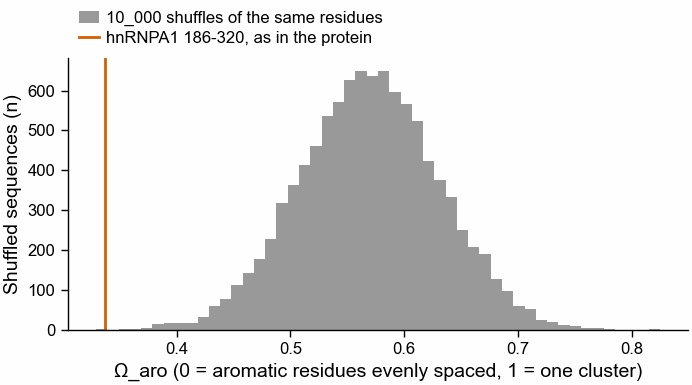

In [7]:
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 50)
ax.hist(
    shuffled_omega,
    bins=50,
    color=pf.GREY,
    label=f"{N_SHUFFLES:_} shuffles of the same residues",
)
ax.axvline(
    lcd_omega,
    color=pf.OKABE_ITO["vermillion"],
    lw=1,
    label=f"hnRNPA1 {LCD_START}-{LCD_END}, as in the protein",
)
ax.set_xlabel("Ω_aro (0 = aromatic residues evenly spaced, 1 = one cluster)")
ax.set_ylabel("Shuffled sequences (n)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
pf.save(fig, FIGURES / "341_omega_aro_hnrnpa1_lcd_vs_shuffles_uniprot")

**How to read it.** Grey bars are shuffles of the same 135 residues; the red line is the real
domain. The real domain sits at the far left: its aromatic residues are more evenly spaced than in
almost every shuffle, as Martin et al. found, so the function reproduces their measure.

## 3. BuGZ (ZNF207) exon 9 (step 7, first part)

Song, Botvinnik et al. 2017 named the serine-rich exon 9 of ZNF207 (BuGZ) as an example of motor
neurons splicing toward more disordered isoforms. Jiang et al. 2015 showed that BuGZ forms liquid
droplets that depend on its hydrophobic residues. Here the exon is found in Ensembl as a pair of protein-coding transcripts that
differ by that one exon. Both proteins are Ensembl translations of transcript models, so these rows are **inferred protein**,
not read from long-read isoforms. Sets A and B-long will show whether the pair is seen in full-length
reads.

In [8]:
lookup = json.loads((DATA / "ensembl_lookup_ZNF207_expand.json").read_text())
tx = {t["display_name"]: t for t in lookup["Transcript"] if t.get("Translation")}
included_name, skipping_name = "ZNF207-203", "ZNF207-204"
included = (DATA / f"ensembl_protein_{included_name}.txt").read_text().strip()
skipping = (DATA / f"ensembl_protein_{skipping_name}.txt").read_text().strip()


def coding_exon_residues(transcript):
    # Residue range (1-based, inclusive) of every coding exon of a + strand transcript.
    tl = transcript["Translation"]
    out, cds_nt = [], 0
    for n, e in enumerate(sorted(transcript["Exon"], key=lambda e: e["start"]), 1):
        s, en = max(e["start"], tl["start"]), min(e["end"], tl["end"])
        if en < s:
            continue
        length = en - s + 1
        out.append(
            {
                "exon_number": n,
                "exon_id": e["id"],
                "chrom_start": e["start"],
                "chrom_end": e["end"],
                "phase": cds_nt % 3,
                "first_residue": cds_nt // 3 + 1,
                "last_residue": (cds_nt + length - 1) // 3 + 1,
            }
        )
        cds_nt += length
    return out


assert tx[included_name]["strand"] == 1
exons_included = coding_exon_residues(tx[included_name])
skipping_exon_ids = {e["id"] for e in tx[skipping_name]["Exon"]}
last_exon = max(e["exon_number"] for e in exons_included)
# First and last exons differ in their untranslated ends, so only internal exons are compared.
missing = [
    e
    for e in exons_included
    if e["exon_id"] not in skipping_exon_ids and 1 < e["exon_number"] < last_exon
]
print(f"{included_name} internal coding exons absent from {skipping_name}:", missing)
exon9 = next(e for e in missing if e["exon_number"] == 9)
start, end = exon9["first_residue"], exon9["last_residue"]
exon_residues = included[start - 1 : end]
assert (
    exon9["phase"] == 0 and (exon9["chrom_end"] - exon9["chrom_start"] + 1) % 3 == 0
), "exon 9 must keep the frame"
assert (
    included[: start - 1] + included[end:] == skipping
), "the skipping protein must be the included one minus exon 9"
print(
    f"exon 9: chr17:{exon9['chrom_start']:_}-{exon9['chrom_end']:_} (GRCh38, + strand), "
    f"{exon9['chrom_end'] - exon9['chrom_start'] + 1} nt, residues {start}-{end} of {included_name} "
    f"({len(included)} aa); {skipping_name} is {len(skipping)} aa; frame-preserving"
)

ZNF207-203 internal coding exons absent from ZNF207-204: [{'exon_number': 9, 'exon_id': 'ENSE00000360903', 'chrom_start': 32366665, 'chrom_end': 32366757, 'phase': 0, 'first_residue': 277, 'last_residue': 307}]
exon 9: chr17:32_366_665-32_366_757 (GRCh38, + strand), 93 nt, residues 277-307 of ZNF207-203 (494 aa); ZNF207-204 is 463 aa; frame-preserving


In [9]:
def block(label, text, first):
    return f"{label:<22}{first:>4} {text} {first + len(text) - 1}"


print(block(f"{included_name} exon 9", exon_residues, start))
print(block("aro_hyd_chg_pol4", cu.encode(exon_residues, cu.ARO_HYD_CHG_POL4), start))
print(block("hp_pbotc_1st_ed2", cu.encode(exon_residues, cu.HP_PBOTC_1ST_ED2), start))
left, right = skipping[start - 11 : start - 1], skipping[start - 1 : start + 9]
print(
    f"{skipping_name} junction  {start - 10:>4} {left} | {right} {start + 9}   (residue {start - 1} joined to residue {start}, which is {end + 1} in {included_name})"
)

rows = []
for what, residues, s, e in [
    ("exon 9", exon_residues, start, end),
    (f"{included_name} (includes exon 9)", included, 1, len(included)),
    (f"{skipping_name} (skips exon 9)", skipping, 1, len(skipping)),
]:
    protein = included if what != f"{skipping_name} (skips exon 9)" else skipping
    rows.append(
        {
            "sequence": what,
            **cu.bulk_scores(residues),
            "iupred_mean": cu.iupred_mean_in_context(protein, s, e),
        }
    )
bugz_scores = pl.DataFrame(rows)
with pl.Config(tbl_cols=-1, tbl_width_chars=250, float_precision=3):
    print(bugz_scores)

ZNF207-203 exon 9      277 MGTPVTSSSTASSNSESLSASSKALFPSTAQ 307
aro_hyd_chg_pol4       277 asssasssssassssdsasassdaafsssas 307
hp_pbotc_1st_ed2       277 hpphhppppphpppppphphppphhhhpphp 307
ZNF207-204 junction   267 TKPLFPSAGQ | AQAAVQGPVG 286   (residue 276 joined to residue 277, which is 308 in ZNF207-203)


shape: (3, 15)
┌──────────────────────────────┬───────────┬───────┬───────────┬────────────────┬───────────────────┬───────────┬───────────────┬────────────────────────┬──────────────┬────────────┬────────────────────────┬────────────────┬───────┬─────────────┐
│ sequence                     ┆ length_aa ┆ kappa ┆ n_charged ┆ aromatic_count ┆ aromatic_fraction ┆ omega_aro ┆ frac_aromatic ┆ frac_other_hydrophobic ┆ frac_charged ┆ frac_polar ┆ net_charge_per_residue ┆ fraction_basic ┆ pI    ┆ iupred_mean │
│ ---                          ┆ ---       ┆ ---   ┆ ---       ┆ ---            ┆ ---               ┆ ---       ┆ ---           ┆ ---                    ┆ ---          ┆ ---        ┆ ---                    ┆ ---            ┆ ---   ┆ ---         │
│ str                          ┆ i64       ┆ f64   ┆ i64       ┆ i64            ┆ f64               ┆ f64       ┆ f64           ┆ f64                    ┆ f64          ┆ f64        ┆ f64                    ┆ f64            ┆ f64   ┆ f64        

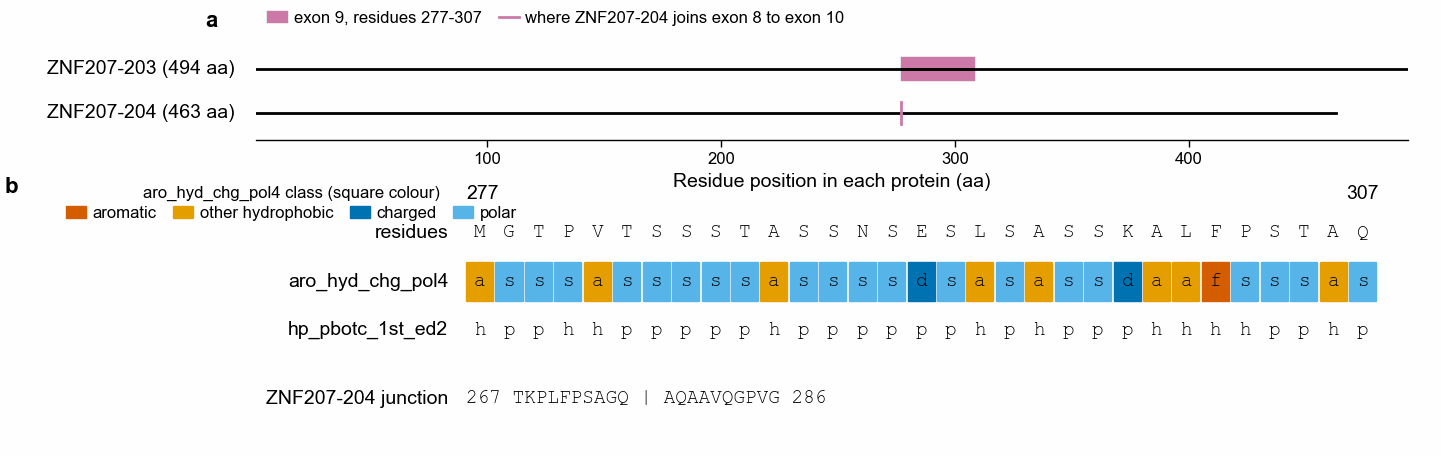

In [10]:
fig = plt.figure(figsize=(pf.TWO_COLUMN_MM * pf.MM, 62 * pf.MM))
ax_line = fig.add_axes([0.16, 0.66, 0.8, 0.2])
ax_res = fig.add_axes([0.02, 0.02, 0.96, 0.5])

# a: proteins as a line, exon 9 as a box
for y, name, length in [
    (1, included_name, len(included)),
    (0, skipping_name, len(skipping)),
]:
    ax_line.plot([1, length], [y, y], color="black", lw=1)
    ax_line.text(-8, y, f"{name} ({length} aa)", ha="right", va="center")
ax_line.add_patch(
    mpatches.Rectangle(
        (start, 0.75), end - start + 1, 0.5, color=pf.OKABE_ITO["reddish_purple"]
    )
)
ax_line.plot([start, start], [-0.25, 0.25], color=pf.OKABE_ITO["reddish_purple"], lw=1)
ax_line.set_xlim(1, len(included))
ax_line.set_ylim(-0.6, 1.6)
ax_line.set_yticks([])
ax_line.spines["left"].set_visible(False)
ax_line.set_xlabel("Residue position in each protein (aa)")
ax_line.legend(
    handles=[
        mpatches.Patch(
            color=pf.OKABE_ITO["reddish_purple"],
            label=f"exon 9, residues {start}-{end}",
        ),
        Line2D(
            [],
            [],
            color=pf.OKABE_ITO["reddish_purple"],
            lw=1,
            label=f"where {skipping_name} joins exon 8 to exon 10",
        ),
    ],
    loc="lower left",
    bbox_to_anchor=(0, 1.05),
    ncol=2,
    frameon=False,
)
pf.panel_label(ax_line, "a")

# b: the residues, each written in both alphabets, coloured by aro_hyd_chg_pol4 class
ax_res.set_xlim(-14, len(exon_residues) + 2)
ax_res.set_ylim(-0.5, 4.5)
ax_res.axis("off")
labels = ["residues", "aro_hyd_chg_pol4", "hp_pbotc_1st_ed2"]
for row, label in enumerate(labels):
    ax_res.text(-0.6, 4 - row, label, ha="right", va="center")
for i, aa in enumerate(exon_residues):
    cls = next(n for n, c in cu.ARO_HYD_CHG_POL4_CLUSTERS.items() if aa in c)
    ax_res.add_patch(mpatches.Rectangle((i, 2.6), 0.92, 0.8, color=CLASS_COLOURS[cls]))
    ax_res.text(i + 0.46, 4, aa, ha="center", va="center", family="monospace")
    ax_res.text(
        i + 0.46,
        3,
        cu.ARO_HYD_CHG_POL4[aa],
        ha="center",
        va="center",
        family="monospace",
    )
    ax_res.text(
        i + 0.46,
        2,
        cu.HP_PBOTC_1ST_ED2[aa],
        ha="center",
        va="center",
        family="monospace",
    )
ax_res.text(0, 4.6, str(start), ha="left", va="bottom")
ax_res.text(len(exon_residues), 4.6, str(end), ha="right", va="bottom")
ax_res.text(-0.6, 0.6, f"{skipping_name} junction", ha="right", va="center")
ax_res.text(
    0,
    0.6,
    f"{start - 10} {left} | {right} {start + 9}",
    ha="left",
    va="center",
    family="monospace",
)
ax_res.legend(
    handles=[
        mpatches.Patch(color=c, label=n.replace("_", " "))
        for n, c in CLASS_COLOURS.items()
    ],
    loc="lower left",
    bbox_to_anchor=(0.0, 0.9),
    ncol=4,
    frameon=False,
    title="aro_hyd_chg_pol4 class (square colour)",
)
pf.panel_label(ax_res, "b")
pf.save(fig, FIGURES / "341_bugz_znf207_exon9_ensembl116_inferred_protein")

**How to read it.** Panel a shows the two Ensembl proteins as lines; the box is exon 9 and the tick
marks where the skipping protein joins exon 8 to exon 10. Panel b writes out the 31 residues of
exon 9 (residues 277-307 of ZNF207-203), the same residues in each reduced alphabet, and the ten
residues on each side of the join in ZNF207-204.

What the exon is made of, from the table above: 20 of 31 residues are polar in
`aro_hyd_chg_pol4` (11 of them serine), one is aromatic (F302), and two are charged (E293, K299).
κ for the exon is 1.0, but it rests on two charged residues, so it says almost nothing; the
`n_charged` column sits next to it for that reason. Exon 9's mean IUPred score is 0.78, above the 0.5
line for disorder and a little above the whole-protein means (0.75 with the exon, 0.76 without). Its
pI is 5.8, so it is acidic, not basic. Skipping it changes the whole protein's
scores by at most 0.007 in any fraction, and its pI by 0.01: on composition alone, exon 9 does not
move the protein.

Exon 9 has no Ω_aro (section 2b): with one aromatic residue in 31 (3%), it is below the 10%
aromatic fraction that Martin et al. 2020 require before computing aromatic spacing.

Not yet done for this example: Ψ in set B-long (needs the nanopore reads processed) and the best
kmerseek hit against PhaSePro and DisProt (needs the index).

## 3b. Exon 9 in the developing neocortex (set A, Patowary et al. 2024)

Set A is long-read sequencing of the germinal zone (GZ, where progenitors divide) and the cortical
plate (CP, where neurons settle) of the human neocortex: three donors, four replicates per region.
Its isoforms (Data S1, `Bulk.gtf`) and per-isoform read counts (Data S2, sheet B) come from Dryad,
downloaded on 2026-10-14 and matching Dryad's SHA-256 checksums. The ZNF207 lines are cached in
`data/341_condensate_exons/`.

The GTF is on **GRCh37**, not GRCh38: ZNF207 starts at chr17:30,677,136 there and at 32,350,157 in
Ensembl 116, and the identifiers carry GENCODE's `_N` lift suffixes. Exon 9 is found by its Ensembl
exon identifier, ENSE00000360903.

Ψ here is computed from isoform read counts: reads of isoforms that contain exon 9, divided by those
reads plus reads of isoforms that join exon 8 directly to exon 10.

In [11]:
EX9_ID = "ENSE00000360903"
gtf_exons = defaultdict(set)
ex9_grch37 = None
for line in (DATA / "patowary2024_dataS1_bulk_ZNF207.gtf").read_text().splitlines():
    fields = line.split("\t")
    if fields[2] != "exon":
        continue
    transcript = re.search(r'transcript_id "([^"]+)"', fields[8]).group(1)
    exon_id = re.search(r'exon_id "([^"]+)"', fields[8]).group(1)
    gtf_exons[transcript].add((int(fields[3]), int(fields[4])))
    if exon_id.split(".")[0] == EX9_ID:
        ex9_grch37 = (int(fields[3]), int(fields[4]))
including = {t for t, e in gtf_exons.items() if ex9_grch37 in e}
upstream_end = max(b for t in including for a, b in gtf_exons[t] if b < ex9_grch37[0])
downstream_start = min(
    a for t in including for a, b in gtf_exons[t] if a > ex9_grch37[1]
)
skipping = {
    t
    for t, e in gtf_exons.items()
    if t not in including
    and any(b == upstream_end for a, b in e)
    and any(a == downstream_start for a, b in e)
}
print(
    f"exon 9 on GRCh37: chr17:{ex9_grch37[0]:_}-{ex9_grch37[1]:_} ({ex9_grch37[1] - ex9_grch37[0] + 1} nt)"
)
print(
    f"{len(gtf_exons)} ZNF207 isoforms; {len(including)} include exon 9; {len(skipping)} join exon 8 "
    f"(ends {upstream_end:_}) to exon 10 (starts {downstream_start:_}): {sorted(skipping)}"
)

counts = pl.read_csv(DATA / "patowary2024_dataS2B_ZNF207_counts.tsv", separator="\t")
samples = [c for c in counts.columns if c.endswith(("_GZ", "_CP"))]
inc_reads = (
    counts.filter(pl.col("transcript_id").is_in(list(including))).select(samples).sum()
)
skip_reads = (
    counts.filter(pl.col("transcript_id").is_in(list(skipping))).select(samples).sum()
)
psi_a = pl.DataFrame(
    [
        {
            "sample": s,
            "donor": s.split("_")[0],
            "region": s.split("_")[-1],
            "reads_including": inc_reads[s][0],
            "reads_skipping": skip_reads[s][0],
        }
        for s in samples
    ]
).with_columns(
    psi=pl.col("reads_including")
    / (pl.col("reads_including") + pl.col("reads_skipping"))
)
psi_by_donor = (
    psi_a.group_by("donor", "region")
    .agg(
        pl.col("reads_including").sum(),
        pl.col("reads_skipping").sum(),
        median_replicate_psi=pl.col("psi").median(),
    )
    .with_columns(
        psi_pooled=pl.col("reads_including")
        / (pl.col("reads_including") + pl.col("reads_skipping"))
    )
    .sort("donor", "region")
)
with pl.Config(tbl_rows=-1):
    print(psi_by_donor)

exon 9 on GRCh37: chr17:30_693_684-30_693_776 (93 nt)
31 ZNF207 isoforms; 23 include exon 9; 2 join exon 8 (ends 30_692_506) to exon 10 (starts 30_694_791): ['ENST00000394673.6_3', 'TALONT000325400']
shape: (6, 6)
┌───────┬────────┬─────────────────┬────────────────┬──────────────────────┬────────────┐
│ donor ┆ region ┆ reads_including ┆ reads_skipping ┆ median_replicate_psi ┆ psi_pooled │
│ ---   ┆ ---    ┆ ---             ┆ ---            ┆ ---                  ┆ ---        │
│ str   ┆ str    ┆ i64             ┆ i64            ┆ f64                  ┆ f64        │
╞═══════╪════════╪═════════════════╪════════════════╪══════════════════════╪════════════╡
│ 209   ┆ CP     ┆ 741             ┆ 10             ┆ 0.988712             ┆ 0.986684   │
│ 209   ┆ GZ     ┆ 467             ┆ 24             ┆ 0.95382              ┆ 0.95112    │
│ 334   ┆ CP     ┆ 1040            ┆ 29             ┆ 0.975826             ┆ 0.972872   │
│ 334   ┆ GZ     ┆ 1168            ┆ 116            ┆ 0.902523    

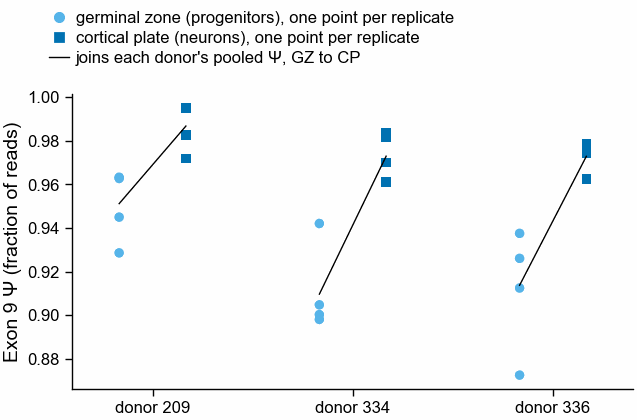

In [12]:
REGION_STYLE = {
    "GZ": dict(
        color=pf.OKABE_ITO["sky_blue"], marker="o", label="germinal zone (progenitors)"
    ),
    "CP": dict(
        color=pf.OKABE_ITO["blue"], marker="s", label="cortical plate (neurons)"
    ),
}
donors = sorted(psi_a["donor"].unique())
fig, ax = plt.subplots(figsize=(pf.ONE_COLUMN_MM * pf.MM, 55 * pf.MM))
for i, donor in enumerate(donors):
    for j, region in enumerate(["GZ", "CP"]):
        vals = psi_a.filter((pl.col("donor") == donor) & (pl.col("region") == region))[
            "psi"
        ].to_list()
        x = i * 3 + j
        ax.scatter(
            [x] * len(vals),
            vals,
            s=12,
            edgecolor="none",
            **{k: v for k, v in REGION_STYLE[region].items() if k != "label"},
        )
    pooled = (
        psi_by_donor.filter(pl.col("donor") == donor)
        .sort("region", descending=True)["psi_pooled"]
        .to_list()
    )
    ax.plot([i * 3, i * 3 + 1], pooled, color="black", lw=0.5)
ax.set_xticks([i * 3 + 0.5 for i in range(len(donors))], [f"donor {d}" for d in donors])
ax.set_xlim(-0.7, len(donors) * 3 - 1.3)
ax.set_ylabel("Exon 9 Ψ (fraction of reads)")
handles = [
    Line2D(
        [],
        [],
        ls="",
        marker=v["marker"],
        color=v["color"],
        label=f"{v['label']}, one point per replicate",
    )
    for v in REGION_STYLE.values()
]
handles.append(
    Line2D([], [], color="black", lw=0.5, label="joins each donor's pooled Ψ, GZ to CP")
)
fig.legend(handles=handles, loc="upper left", frameon=False, bbox_to_anchor=(0.12, 1.0))
fig.subplots_adjust(top=0.78, left=0.17, bottom=0.1, right=0.97)
pf.save(fig, FIGURES / "341_bugz_exon9_psi_gz_vs_cp_patowary2024_grch37")

**How to read it.** Each point is one replicate's Ψ; the line joins a donor's pooled Ψ in the
germinal zone to the cortical plate. Higher means more of ZNF207's transcripts include exon 9.

In all three donors exon 9 is included more in the cortical plate than in the germinal zone. It is
mostly included in both regions, so the change is in the small fraction that skips it. This is the
same direction as Song, Botvinnik et al. 2017 (neurons include it more), now seen in full-length
reads from human tissue instead of short reads from cultured cells. Three donors is too few for a
test on this one exon; the genome-wide comparison in step 6a is where the direction gets tested.

## Data sources

| What | Source | Version | Fetched |
|---|---|---|---|
| ZNF207 transcripts and proteins | Ensembl REST `lookup/symbol/homo_sapiens/ZNF207?expand=1`, `sequence/id` | release 116, GRCh38.p14 | 2026-10-14 |
| Run lists | ENA portal `filereport` for PRJDB19918 and PRJNA947248 | as served | 2026-10-14 |
| Dataset access | each paper's data-availability section and repository page, in `dataset_access.tsv` | | 2026-10-14 |
| κ | localCIDER 0.1.21; reproduces κ = 0.0009 for (EK)25 and 1.0 for E25K25 (Das and Pappu 2013) | | |
| IUPred | `iupred_string.c` from InterProScan's `bin/mobidb/idrpred/bin/IUPred/src.zip` (sha256 `7caac3c1…`), long mode, compiled with Apple clang | | |
| pI | Biopython 1.88 `ProteinAnalysis.isoelectric_point` | | |
| Set A isoforms and counts | Dryad doi:10.5061/dryad.0rxwdbs68 (Patowary et al. 2024), Data S1 `Bulk.gtf` and Data S2 sheet B; ZNF207 lines cached | GRCh37 coordinates | 2026-10-14 |
| Ω_aro | localCIDER 0.1.21 `get_kappa_X(["F", "W", "Y"])`, as Martin et al. 2020 describe in their supplement | | |
| hnRNPA1 sequence | UniProt P09651 FASTA | release 2026_03 | 2026-10-14 |

## References

Das, Rahul K., and Rohit V. Pappu. "Conformations of Intrinsically Disordered Proteins Are
Influenced by Linear Sequence Distributions of Oppositely Charged Residues." *Proceedings of the
National Academy of Sciences* 110, no. 33 (2013): 13392–97. https://doi.org/10.1073/pnas.1304749110.

Jiang, Hao, et al. "Phase Transition of Spindle-Associated Protein Regulate Spindle Apparatus
Assembly." *Cell* 163, no. 1 (2015): 108–22. https://doi.org/10.1016/j.cell.2015.08.010.

Martin, Erik W., et al. "Valence and Patterning of Aromatic Residues Determine the Phase Behavior of
Prion-like Domains." *Science* 367, no. 6478 (2020): 694–99. https://doi.org/10.1126/science.aaw8653.

Song, Yan, Olga B. Botvinnik, et al. "Single-Cell Alternative Splicing Analysis with Expedition
Reveals Splicing Dynamics during Neuron Differentiation." *Molecular Cell* 67, no. 1 (2017):
148–161.e5. https://doi.org/10.1016/j.molcel.2017.06.003.

Patowary, Ashok, et al. "Developmental Isoform Diversity in the Human Neocortex Informs
Neuropsychiatric Risk Mechanisms." *Science* 384, no. 6698 (2024): eadh7688.
https://doi.org/10.1126/science.adh7688.

Tanaka, Yoshihisa, Naohiro Sunamura, Rei Kajitani, Marie Ikeguchi, and Ryo Kunimoto. "Long-Read RNA
Sequencing Unveils a Novel Cryptic Exon in MNAT1 along with Its Full-Length Transcript Structure in
TDP-43 Proteinopathy." *Communications Biology* 8 (2025): 1056.
https://doi.org/10.1038/s42003-025-08463-4.

Yang, Yalan, Runwei Yang, Bowei Kang, Sheng Qian, Xin He, and Xiaochang Zhang. "Single-Cell
Long-Read Sequencing in Human Cerebral Organoids Uncovers Cell-Type-Specific and Autism-Associated
Exons." *Cell Reports* 42, no. 11 (2023): 113335. https://doi.org/10.1016/j.celrep.2023.113335.

Ma, X. Rosa, et al. "TDP-43 Represses Cryptic Exon Inclusion in the FTD–ALS Gene UNC13A." *Nature*
603, no. 7899 (2022): 124–30. https://doi.org/10.1038/s41586-022-04424-7.

Baxi, Emily G., et al. "Answer ALS, a Large-Scale Resource for Sporadic and Familial ALS Combining
Clinical and Multi-Omics Data from Induced Pluripotent Cell Lines." *Nature Neuroscience* 25, no. 2 (2022):
226–37. https://doi.org/10.1038/s41593-021-01006-0.